# Calibration and threshold selection on Validation B

E4 uses the frozen CatBoost baseline. Fit only a sigmoid calibrator on B, then choose a calibrated probability threshold with Recall >=70%, maximum Precision, lowest alert rate and largest threshold. B is reused for both decisions: all B scores below are descriptive fitting/selection scores. Do not predict Test in this notebook.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Load the frozen selection and verify hashes

Use the explicitly selected classifier and matching environment. Do not refit preprocessing or CatBoost.

In [2]:
from scipy.special import logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_recall_curve, confusion_matrix, precision_score, recall_score, f1_score,
)
import warnings

SELECTION_PATH = ROOT / "outputs/tables/machine_learning/ml_selection/20261111_154450_762570/selected_config.json"
selection = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
assert selection["selected_model"] == "CatBoost" and selection["weighting"] == "none"
model_path = ROOT / selection["frozen_pipeline"]
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == selection["pipeline_sha256"]
for name, digest in selection["input_hashes"].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest, name
for name, version in selection["source_package_versions"].items():
    if name != "python":
        assert importlib.metadata.version(name) == version, name
frozen_pipeline = joblib.load(model_path)
assert frozen_pipeline.named_steps["classifier"].get_params() == selection["parameters"]


## Load Validation B only

Filter by the existing manifest before predicting. Confirm the expected 3,115 orders and 180 Late labels. Do not predict Train, A or Test.

In [3]:
features = selection["features"]
cat = selection["categorical_features"]
num = [name for name in features if name not in cat]
data = pd.read_csv(ROOT / "data/processed/research_data_weather_price_holiday_assume_utc.csv")
manifest = pd.read_csv(ROOT / "data/ml_preparation/split_manifest.csv")
assert data.order_id.is_unique and manifest.order_id.is_unique
b_orders = manifest.loc[manifest.split.eq("validation_b"), ["order_id", "split"]]
b = b_orders.merge(data, on="order_id", how="left", validate="one_to_one", indicator=True)
assert b["_merge"].eq("both").all() and len(b) == 3115
assert b.is_late.isin([0, 1]).all() and b.is_late.eq(1).sum() == 180
for name in cat:
    b[name] = b[name].map(lambda value: str(value) if pd.notna(value) else np.nan)
for name in num:
    b[name] = pd.to_numeric(b[name], errors="raise").replace([np.inf, -np.inf], np.nan)
y_b = b.is_late.astype(int).to_numpy()
display(pd.DataFrame([dict(split="validation_b", n=len(b), late=int(y_b.sum()), prevalence=float(y_b.mean()))]))


,split,n,late,prevalence
0,validation_b,3115,180,0.057785


## Declare the calibration and threshold procedure

Write the full plan before fitting the calibrator. The input classifier is already frozen; no parameter or probability-type search is performed.

In [4]:
EPSILON = 1e-6
MIN_RECALL = 0.70
calibrator = LogisticRegression(
    penalty=None, solver="lbfgs", max_iter=1000, tol=1e-10,
    fit_intercept=True, class_weight=None, random_state=42,
)
run = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
tables = ROOT / "outputs/tables/machine_learning/ml_calibration" / run
models = ROOT / "outputs/models/ml_calibration" / run
figures = ROOT / "outputs/figures/ml_calibration" / run
for directory in [tables, models, figures]:
    directory.mkdir(parents=True, exist_ok=False)
plan = dict(
    selection=SELECTION_PATH.relative_to(ROOT).as_posix(),
    selection_sha256=hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest(),
    method="sigmoid on clipped raw log-odds", clipping_epsilon=EPSILON,
    calibrator_parameters=calibrator.get_params(),
    calibration_split="validation_b", threshold_split="validation_b",
    threshold_probability_type="calibrated", threshold_rule="p >= threshold",
    min_recall=MIN_RECALL,
    threshold_selection="max precision, then min alert rate, then max threshold",
    calibration_bins="10 equal-width bins, [left,right), last includes 1",
    classifier_refitted=False, test_predicted=False,
    limitation="B is used for calibration fitting and threshold selection; its scores are not independent evaluation.",
)
(tables / "calibration_plan.json").write_text(json.dumps(plan, indent=2), encoding="utf-8")


1151

## Predict B and fit the sigmoid calibrator

Fit only the mapping sigmoid(a * logit(raw_probability) + b). No eval_set or training call is made on the CatBoost pipeline.

In [5]:
raw_probability = frozen_pipeline.predict_proba(b[features])[:, 1]
assert np.isfinite(raw_probability).all() and ((raw_probability >= 0) & (raw_probability <= 1)).all()
log_odds_b = logit(np.clip(raw_probability, EPSILON, 1 - EPSILON)).reshape(-1, 1)
with warnings.catch_warnings(record=True) as calibration_warnings:
    warnings.simplefilter("always")
    calibrator.fit(log_odds_b, y_b)
assert calibrator.n_iter_.max() < calibrator.max_iter, "Sigmoid optimizer reached the iteration limit."
calibrated_probability = calibrator.predict_proba(log_odds_b)[:, 1]
assert np.isfinite(calibrated_probability).all()
assert ((calibrated_probability >= 0) & (calibrated_probability <= 1)).all()
print("Sigmoid slope:", float(calibrator.coef_[0, 0]))
print("Sigmoid intercept:", float(calibrator.intercept_[0]))
for warning in calibration_warnings:
    print(type(warning.message).__name__ + ": " + str(warning.message))


Sigmoid slope: 1.2082256457876963
Sigmoid intercept: 1.493376232731434


## Compare raw and calibrated probabilities

All scores in this notebook use B, which also fits the calibrator. Do not interpret an improvement here as independent evidence of generalisation.

In [6]:
comparison_rows = []
for probability_type, probabilities in [("raw", raw_probability), ("calibrated", calibrated_probability)]:
    comparison_rows.append(dict(
        model="CatBoost", split="validation_b", probability_type=probability_type,
        n=len(b), late=int(y_b.sum()), prevalence=float(y_b.mean()),
        mean_probability=float(probabilities.mean()),
        AP=average_precision_score(y_b, probabilities),
        ROC_AUC=roc_auc_score(y_b, probabilities),
        Brier=brier_score_loss(y_b, probabilities),
        LogLoss=log_loss(y_b, probabilities, labels=[0, 1]),
    ))
calibration_comparison = pd.DataFrame(comparison_rows)
calibration_comparison.to_csv(tables / "calibration_comparison.csv", index=False)
display(calibration_comparison)


,model,split,probability_type,n,late,prevalence,mean_probability,AP,ROC_AUC,Brier,LogLoss
0,CatBoost,validation_b,raw,3115,180,0.057785,0.027490,0.131758,0.747929,0.054102,0.216864
1,CatBoost,validation_b,calibrated,3115,180,0.057785,0.057785,0.131758,0.747929,0.052955,0.202936


## Enumerate and select the operating threshold

Evaluate all distinct calibrated probabilities with predicted Late defined as p >= threshold. Persist the full candidate table to make selection reviewable.

In [7]:
precision, recall, thresholds = precision_recall_curve(y_b, calibrated_probability)
alert_counts = len(y_b) - np.searchsorted(np.sort(calibrated_probability), thresholds, side="left")
tp = np.rint(recall[:-1] * y_b.sum()).astype(int)
fp = alert_counts - tp
fn = int(y_b.sum()) - tp
tn = len(y_b) - tp - fp - fn
threshold_candidates = pd.DataFrame(dict(
    threshold=thresholds, Precision=precision[:-1], Recall=recall[:-1],
    alert_rate=alert_counts / len(y_b), alerts=alert_counts,
    TN=tn, FP=fp, FN=fn, TP=tp,
))
threshold_candidates["eligible"] = threshold_candidates.Recall.ge(MIN_RECALL)
threshold_candidates.to_csv(tables / "threshold_candidates.csv", index=False)
eligible = threshold_candidates.loc[threshold_candidates.eligible]
assert not eligible.empty
best = eligible.sort_values(["Precision", "alert_rate", "threshold"], ascending=[False, True, False]).iloc[0]
threshold = float(best.threshold)
predicted = (calibrated_probability >= threshold).astype(int)
actual_tn, actual_fp, actual_fn, actual_tp = confusion_matrix(y_b, predicted, labels=[0, 1]).ravel()
threshold_metrics = dict(
    model="CatBoost", split="validation_b", probability_type="calibrated",
    threshold=threshold, min_recall=MIN_RECALL,
    Precision=precision_score(y_b, predicted, zero_division=0),
    Recall=recall_score(y_b, predicted), F1=f1_score(y_b, predicted),
    alert_rate=float(predicted.mean()), alerts=int(predicted.sum()),
    TN=int(actual_tn), FP=int(actual_fp), FN=int(actual_fn), TP=int(actual_tp),
    n=len(y_b), late=int(y_b.sum()),
)
assert threshold_metrics["Recall"] >= MIN_RECALL
np.testing.assert_array_equal([actual_tn, actual_fp, actual_fn, actual_tp], best[["TN", "FP", "FN", "TP"]].to_numpy(dtype=int))
pd.DataFrame([threshold_metrics]).to_csv(tables / "threshold_metrics.csv", index=False)
display(pd.DataFrame([threshold_metrics]))


,model,split,probability_type,threshold,min_recall,Precision,Recall,F1,alert_rate,alerts,TN,FP,FN,TP,n,late
0,CatBoost,validation_b,calibrated,0.054179,0.7,0.109683,0.711111,0.190052,0.374639,1167,1896,1039,52,128,3115,180


## Plot calibration and the operating point

Use 10 fixed equal-width bins. Keep empty bins with n=0 and missing mean/observed rate; export the counts for interpreting sparse bins.

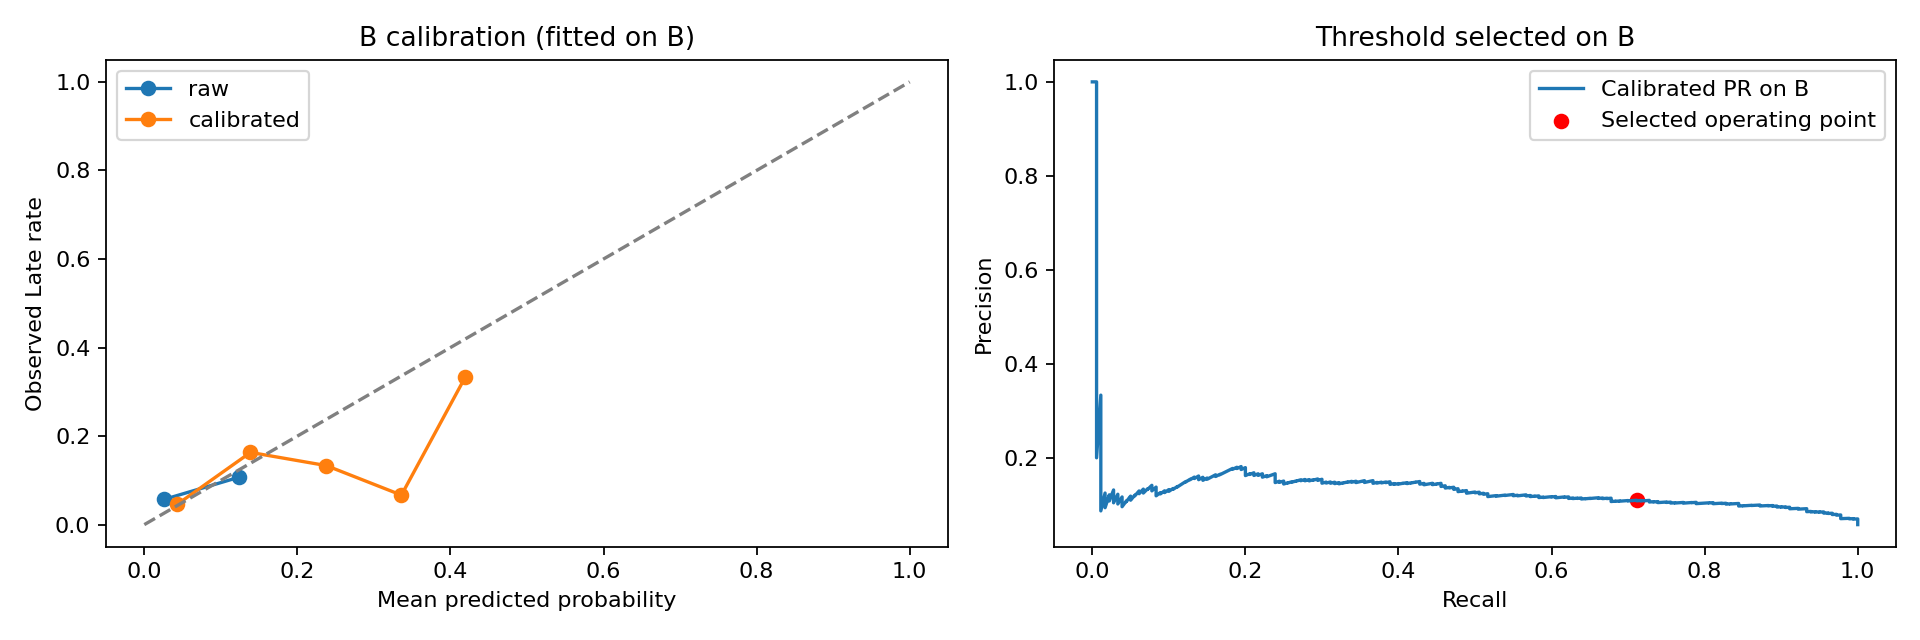

,probability_type,bin,left,right,n,late,mean_probability,observed_rate
0,raw,0,0.0,0.1,3059,174,0.025724,0.056881
1,raw,1,0.1,0.2,56,6,0.123928,0.107143
2,raw,2,0.2,0.3,0,0,NaN,NaN
3,raw,3,0.3,0.4,0,0,NaN,NaN
4,raw,4,0.4,0.5,0,0,NaN,NaN
5,raw,5,0.5,0.6,0,0,NaN,NaN
6,raw,6,0.6,0.7,0,0,NaN,NaN
7,raw,7,0.7,0.8,0,0,NaN,NaN
8,raw,8,0.8,0.9,0,0,NaN,NaN
9,raw,9,0.9,1.0,0,0,NaN,NaN


In [8]:
bin_rows = []
for kind, probabilities in [("raw", raw_probability), ("calibrated", calibrated_probability)]:
    codes = np.minimum((probabilities * 10).astype(int), 9)
    for index in range(10):
        mask = codes == index
        bin_rows.append(dict(
            probability_type=kind, bin=index, left=index / 10, right=(index + 1) / 10,
            n=int(mask.sum()), late=int(y_b[mask].sum()),
            mean_probability=float(probabilities[mask].mean()) if mask.any() else np.nan,
            observed_rate=float(y_b[mask].mean()) if mask.any() else np.nan,
        ))
calibration_bins = pd.DataFrame(bin_rows)
calibration_bins.to_csv(tables / "calibration_bins.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind, group in calibration_bins.groupby("probability_type", sort=False):
    valid = group.loc[group.n.gt(0)]
    axes[0].plot(valid.mean_probability, valid.observed_rate, marker="o", label=kind)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed Late rate", title="B calibration (fitted on B)")
axes[0].legend()
axes[1].plot(recall, precision, label="Calibrated PR on B")
axes[1].scatter([threshold_metrics["Recall"]], [threshold_metrics["Precision"]], color="red", label="Selected operating point")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Threshold selected on B")
axes[1].legend()
fig.tight_layout()
plot_path = figures / "calibration_and_threshold.png"
fig.savefig(plot_path, dpi=160)
display(Image(filename=str(plot_path)))
plt.close(fig)
display(calibration_bins)


## Freeze the calibrator and threshold for final Test

Save a separate E4 record linked by hash to the immutable E3 record. Test must later apply the exact transform, calibrator and threshold below, without refitting.

In [9]:
calibrator_path = models / "sigmoid_calibrator.joblib"
joblib.dump(calibrator, calibrator_path)
np.testing.assert_allclose(joblib.load(calibrator_path).predict_proba(log_odds_b)[:, 1], calibrated_probability, rtol=1e-12, atol=1e-14)
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == selection["pipeline_sha256"]
for name, digest in selection["input_hashes"].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest
b_predictions = pd.DataFrame(dict(
    order_id=b.order_id.to_numpy(), split="validation_b", y_true=y_b,
    raw_probability=raw_probability, calibrated_probability=calibrated_probability,
    prediction=predicted, threshold=threshold,
))
b_predictions.to_csv(tables / "validation_b_predictions.csv", index=False)
final_config = dict(
    status="frozen_ready_for_test", model="CatBoost", configuration="unweighted_baseline",
    selection_config=SELECTION_PATH.relative_to(ROOT).as_posix(),
    selection_sha256=plan["selection_sha256"],
    frozen_pipeline=selection["frozen_pipeline"], pipeline_sha256=selection["pipeline_sha256"],
    features=features, categorical_features=cat, input_hashes=selection["input_hashes"],
    calibrator=calibrator_path.relative_to(ROOT).as_posix(),
    calibrator_sha256=hashlib.sha256(calibrator_path.read_bytes()).hexdigest(),
    calibration_method="sigmoid on clipped log-odds", clipping_epsilon=EPSILON,
    slope=float(calibrator.coef_[0, 0]), intercept=float(calibrator.intercept_[0]),
    calibrator_parameters=calibrator.get_params(), threshold=threshold,
    threshold_probability_type="calibrated", prediction_rule="p >= threshold",
    threshold_rule=plan["threshold_selection"], min_recall=MIN_RECALL,
    validation_b_metrics=threshold_metrics,
    package_versions={**{name: importlib.metadata.version(name) for name in selection["source_package_versions"] if name != "python"}, "python": platform.python_version()},
    classifier_refitted=False, test_predicted=False,
    limitation=plan["limitation"],
)
(tables / "final_config.json").write_text(json.dumps(final_config, indent=2), encoding="utf-8")
print("Frozen calibration/threshold record:", (tables / "final_config.json").relative_to(ROOT))
print("CatBoost pipeline unchanged. Test remains unscored.")


Frozen calibration/threshold record: outputs\tables\ml_calibration\20261111_154951_108593\final_config.json
CatBoost pipeline unchanged. Test remains unscored.
